we are going to create and visualise Bell-state entanglement using Qiskit. The goal is to understand how a Hadamard gate and a CNOT gate can connect two qubits into an entangled state, and then use simulation and visualisation to observe the resulting measurement correlations.

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_state_city

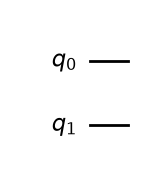

In [3]:
bell_circuit = QuantumCircuit(2)

bell_circuit.draw("mpl")

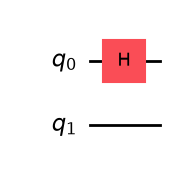

In [4]:
bell_circuit.h(0)

bell_circuit.draw("mpl")

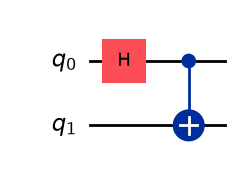

In [5]:
bell_circuit.cx(0, 1)

bell_circuit.draw("mpl")

In [6]:
bell_state = Statevector.from_instruction(bell_circuit)

print(bell_state)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


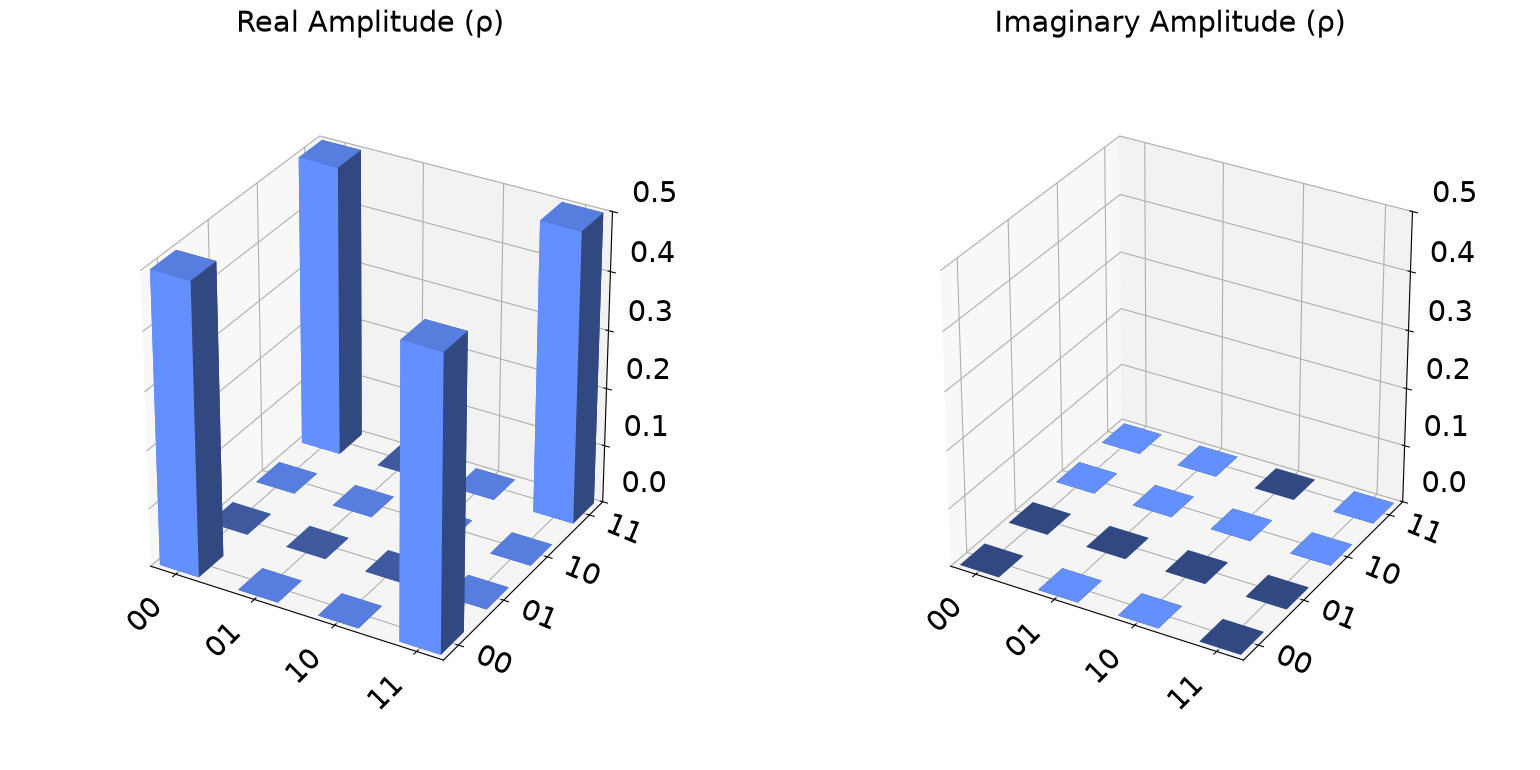

In [7]:
plot_state_city(bell_state)

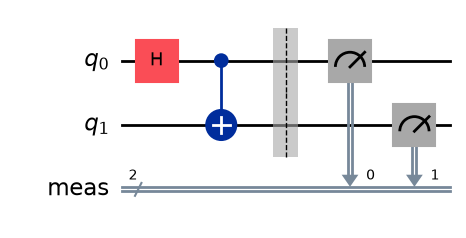

In [8]:
measured_circuit = bell_circuit.copy()

measured_circuit.measure_all()

measured_circuit.draw("mpl")

In [9]:
simulator = AerSimulator()

In [10]:
result = simulator.run(
    measured_circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'11': 492, '00': 508}


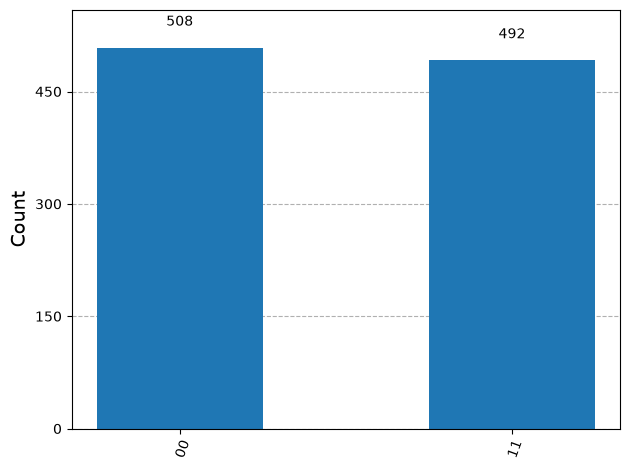

In [11]:
plot_histogram(counts)

In [12]:
total_shots = sum(counts.values())

probability_00 = counts.get("00", 0) / total_shots
probability_11 = counts.get("11", 0) / total_shots

correlated_probability = probability_00 + probability_11

print(f"Probability of |00>: {probability_00:.2%}")
print(f"Probability of |11>: {probability_11:.2%}")
print(f"Total correlated outcomes: {correlated_probability:.2%}")

Probability of |00>: 50.80%
Probability of |11>: 49.20%
Total correlated outcomes: 100.00%


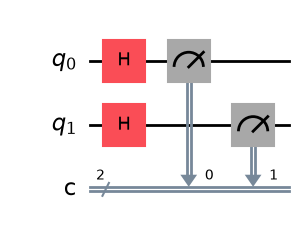

In [13]:
independent_circuit = QuantumCircuit(2, 2)

independent_circuit.h(0)
independent_circuit.h(1)

independent_circuit.measure([0, 1], [0, 1])

independent_circuit.draw("mpl")

In [14]:
independent_result = simulator.run(
    independent_circuit,
    shots=1000
).result()

independent_counts = independent_result.get_counts()

print(independent_counts)

{'01': 258, '10': 276, '00': 216, '11': 250}


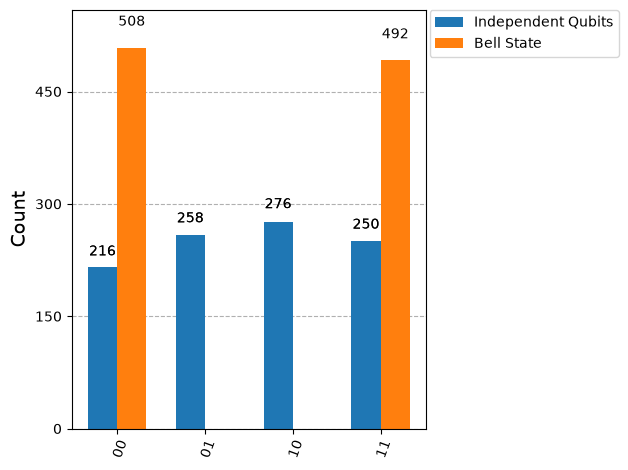

In [15]:
plot_histogram(
    [independent_counts, counts],
    legend=["Independent Qubits", "Bell State"]
)